so previously we peformed EDA on the data of data and extracted a csv out of the clean version . 
The clean version now will be used for model building, pipelines , metric evluation and hyper-parameter tuning. 

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 

path=Path.cwd()
file_path=path.parent/'Data'/'cleaned_data.csv'
data=pd.read_csv(file_path)
df=data.copy()
df

,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],MachineFailure
0,M14860,M,298.1,308.6,1551,42.8,0,0
1,L47181,L,298.2,308.7,1408,46.3,3,0
2,L47182,L,298.1,308.5,1498,49.4,5,0
3,L47183,L,298.2,308.6,1433,39.5,7,0
4,L47184,L,298.2,308.7,1408,40.0,9,0
...,...,...,...,...,...,...,...,...
9995,M24855,M,298.8,308.4,1604,29.5,14,0
9996,H39410,H,298.9,308.4,1632,31.8,17,0
9997,M24857,M,299.0,308.6,1645,33.4,22,0
9998,H39412,H,299.0,308.7,1408,48.5,25,0


In [2]:
# There are class imbalance as discussed during eda! 
df['MachineFailure'].value_counts()

MachineFailure
0    9661
1     339
Name: count, dtype: int64

In [3]:
# but initially we will see how baseline models would work .

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, accuracy_score,confusion_matrix
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.compose import ColumnTransformer


In [5]:
# initaily with imbalnce class we are experimenting . 

demo=data.copy()
demo.head()

,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],MachineFailure
0,M14860,M,298.1,308.6,1551,42.8,0,0
1,L47181,L,298.2,308.7,1408,46.3,3,0
2,L47182,L,298.1,308.5,1498,49.4,5,0
3,L47183,L,298.2,308.6,1433,39.5,7,0
4,L47184,L,298.2,308.7,1408,40.0,9,0


In [6]:
x=demo.drop('MachineFailure',axis=1)
y=demo['MachineFailure']

In [7]:
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.2, random_state=42,stratify=y)
# stratify=y ensures that the training and testing sets maintain approximately the same class distribution as the original target variable (y).

In [8]:
numerical_col=[
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]


transform=ColumnTransformer(transformers=[('tnf1',StandardScaler(),numerical_col),
                                          ('tnf2',OneHotEncoder(sparse_output=False,handle_unknown='ignore'),['Type'])],remainder='drop')


# product ID is just unique identifier so we didnt encode it 

x_train_transformed = transform.fit_transform(xtrain)
x_test_transformed = transform.transform(xtest)


x_train_transformed

array([[ 0.99891359,  0.60428162, -0.46060741, ...,  0.        ,
         0.        ,  1.        ],
       [-1.50519408, -1.15325984, -0.77557391, ...,  0.        ,
         0.        ,  1.        ],
       [ 0.49809206,  1.07746586, -1.00765448, ...,  0.        ,
         0.        ,  1.        ],
       ...,
       [ 0.14751698,  1.00986812, -0.41640159, ...,  1.        ,
         0.        ,  0.        ],
       [ 0.84866713,  0.80707487, -0.12353801, ...,  0.        ,
         1.        ,  0.        ],
       [-0.65379747, -0.20689136, -0.42745305, ...,  0.        ,
         1.        ,  0.        ]], shape=(8000, 8))

In [9]:
linear=LogisticRegression()
linear.fit(x_train_transformed,ytrain)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [10]:
predict=linear.predict(x_test_transformed)
print(accuracy_score(ytest,predict))
print("reacll",recall_score(ytest,predict))
print("precision",precision_score(ytest,predict))

0.9675
reacll 0.10294117647058823
precision 0.6363636363636364


In [11]:
confusion_matrix(ytest,predict,labels=[1,0])

array([[   7,   61],
       [   4, 1928]])

In [12]:
dt=DecisionTreeClassifier(criterion='gini')
dt.fit(x_train_transformed,ytrain)
dtpred=dt.predict(x_test_transformed)
print(accuracy_score(ytest,dtpred))
print("recall",recall_score(ytest,dtpred))
print("precision",precision_score(ytest,dtpred))

0.9765
recall 0.6764705882352942
precision 0.647887323943662


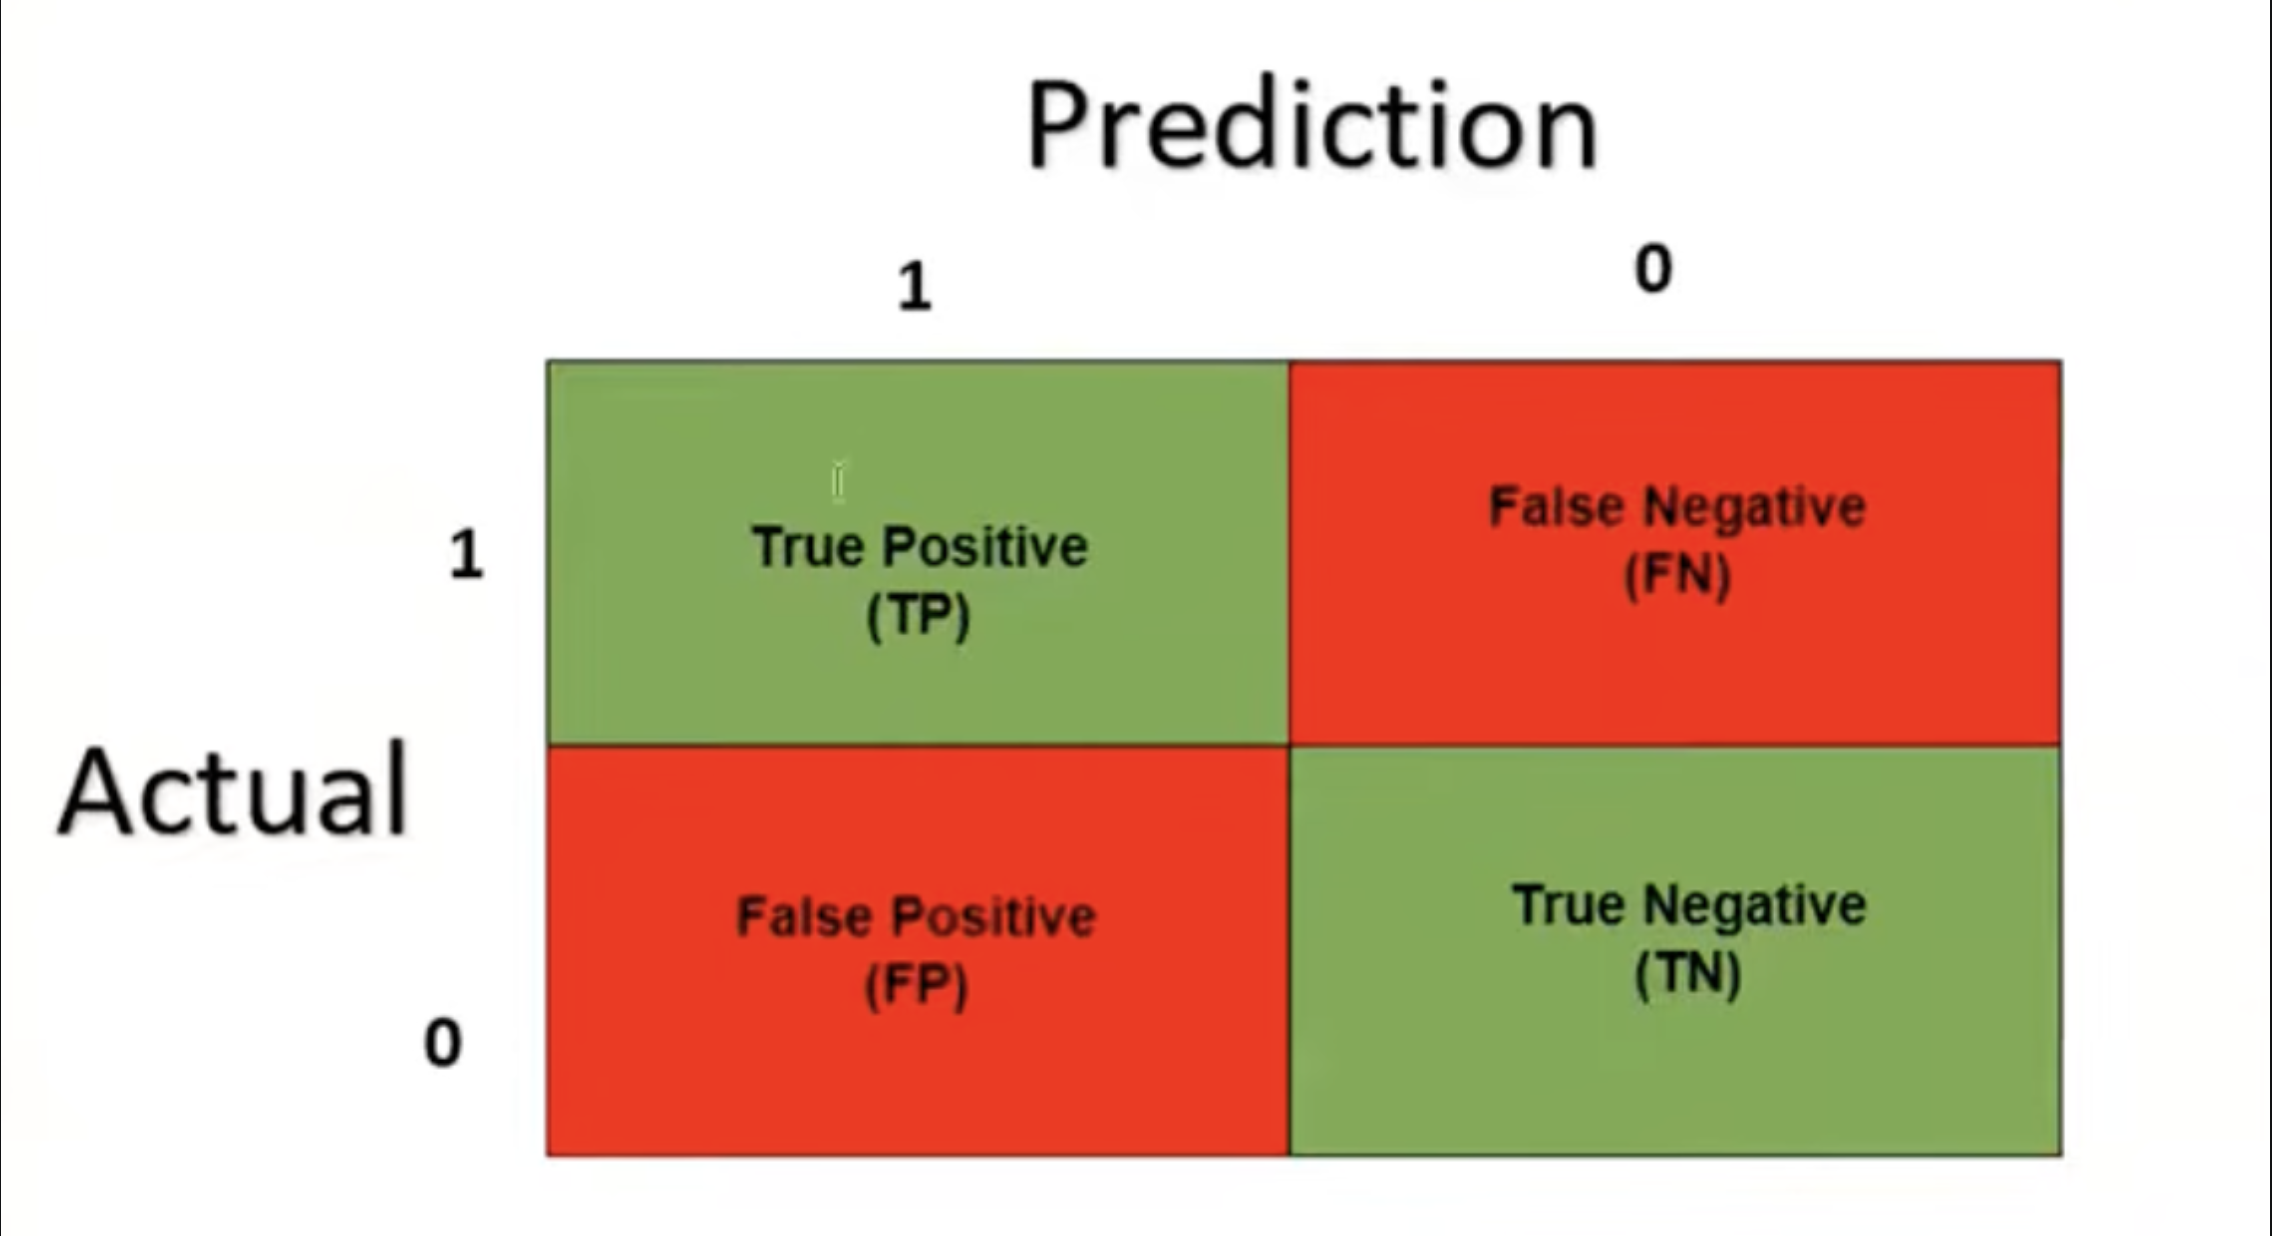

In [13]:
confusion_matrix(ytest,dtpred,labels=[1,0])

array([[  46,   22],
       [  25, 1907]])

Our model is made for predicting whether the machine fails or not based on the given input feature to it ..

so the problem is :

- Tp: machine actually fails and predicts also it fails 
- Fn: the machine actually fails but the model says it dosen't fails 
- Fp: the machine dosent fails but model predicts it fails 
- Tn: the machine dosent fail and model also predicts the machine dosent fails 



so the problem for us is that
> Machine acutally fails and the model can't predict it might fail,  as we might rely on model and be stress free but it might fail and cause serious issue .. 

> if the model dosen't fails but model predicted the machine fails then thats not a problelm , we will check aftwerwards and be sure that machine is good and wont fail ..


-->>> But making unnecessary checks also cause money so much Fp error is also not acceptable from business point of view ..
so we have to consider the model with high recall and acceptable precision score. 
 

so in the above baseline model we tested with , letting the target labels remain unbalanced , we found that the logistic regression model made more (45) and Decision Tree made less (15) precision error , 
> so if we had to select between two models we would choose the Decesion tree model and acutally it also has more accuracy score too .. 

now we will move to , balanced.ipynb where we will solve this class imbalanced problem and work with model and pipelines 

#